# Pipeline comparison 2025 (S1A + S1C): COMPASS-Dolphin vs ISCE2-Dolphin-MintPy

Both pipelines processed the **same 23 acquisitions** of track 073 ascending (IW1 + IW2, VV),
2025-01-09 – 2025-06-26. From 2025-03-28 on, Sentinel-1A and Sentinel-1C alternate every 6 days.

| Pipeline | Coregistration | Time series / velocity | Corrections |
|---|---|---|---|
| **COMPASS-Dolphin** | COMPASS geocoded burst SLCs (geometric coregistration, **no ESD**) | Dolphin (whirlwind unwrapping, L1 inversion) | none |
| **ISCE2-Dolphin-MintPy** | ISCE2 topsStack with **NESD** (network enhanced spectral diversity) | Dolphin phase linking + SNAPHU, MintPy inversion | ERA5 troposphere, quadratic deramp, DEM error |

**Question.** In earlier runs, the S1C dates showed phase jumps at burst (and subswath) edges: a small azimuth
misregistration between S1A and S1C becomes a phase ramp in TOPS bursts that jumps from one burst to the next.
ESD estimates exactly this azimuth offset, so the ISCE2 run should be free of the jumps.
Is that the case, and does the new COMPASS-Dolphin run still show them?

**Workflow**
1. Processing metadata of both runs side by side; mission (S1A / S1C) per date.
2. Load the points inside the AOI: coordinates, coherence, velocity and the full time series.
   The time series are re-referenced to the same first date and a velocity is fitted the same way for both.
3. Aggregate onto a common 40 m grid (as in notebook 03).
4. Compare the velocities of the two pipelines (aligned on commonly stable cells).
5. **S1A / S1C burst-edge check** (method of `dolphin/dolphin_results_explorer.ipynb`, section 4):
   offset maps, and step across each edge per date and per pipeline.
6. Compare the time series per date: do the pipelines disagree more on S1C dates?

**Code**: readers, metrics, grid and alignment from `aducat_val` (`src/aducat_val/`); the step fit across edges
is specific to this question and stays in the notebook.

**Conventions**: LOS displacements in mm, velocities in mm/yr; negative = away from the satellite.
Differences between pipelines are always `ISCE2 − COMPASS`. A *step* across an edge is
`first side − second side` (e.g. north − south) at the edge itself.

In [1]:
import sys
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyarrow.parquet as pq
from IPython.display import display
from matplotlib.cm import ScalarMappable
from matplotlib.colors import LogNorm, Normalize
from matplotlib.lines import Line2D
from pyproj import Transformer

try:
    import aducat_val
except ImportError:  # package not installed with `pip install -e .`: use src/ of this repo (see README.md)
    repo_root = next(p for p in Path.cwd().resolve().parents if (p / "src" / "aducat_val").is_dir())
    sys.path.insert(0, str(repo_root / "src"))

from aducat_val import alignment, metrics, readers, spatial
from aducat_val import display as adisplay
from aducat_val.config import METRIC_CRS, VELOCITY_CMAP
from aducat_val.display import metrics_box, show
from aducat_val.metrics import nmad
from aducat_val.spatial import inside
from aducat_val.spatial import line_coordinates as edge_coords
from aducat_val.spatial import line_side_names as side_names

## Configuration

In [2]:
# ---- Paths: set them to where the data is on your machine ----
DATA_DIR = Path("/home/lukas/projects/ADUCAT/data")
AOI_FILE = DATA_DIR / "AOI/Projektgebiet_ADUCAT-AOI.gpkg"

STACK = "S1_ASC_073_IW1-IW2_VV_20250109_20250626_vienna"

# name -> options of the source function in aducat_val/readers.py
# velocity  : velocity column of the provider [mm/yr] (only for reference, the comparison uses a common fit)
# coherence : quality column. Not the same quantity: COMPASS = Dolphin temporal coherence,
#             ISCE2 = MintPy temporal coherence of the network inversion
PIPELINES = readers.sources({
    "COMPASS-Dolphin": dict(file=DATA_DIR / f"final_outputs/COMPASS-DOLPHIN/{STACK}.parquet"),
    "ISCE2-Dolphin-MintPy": dict(file=DATA_DIR / f"final_outputs/isce2-dolphin-mintpy/{STACK}.parquet"),
})
FIRST, SECOND = list(PIPELINES)          # differences are SECOND − FIRST
SHORT = {"COMPASS-Dolphin": "COMPASS", "ISCE2-Dolphin-MintPy": "ISCE2"}

# Points with a lower coherence are dropped right after loading
MIN_COHERENCE = {"COMPASS-Dolphin": 0.7, "ISCE2-Dolphin-MintPy": 0.7}

# Grid and comparison settings (as in t2_city_wide_velocity; grid CRS = METRIC_CRS from aducat_val.config)
GRID_SIZE_M = 40
MIN_POINTS_PER_CELL = 1
ALIGN_TO_STABLE = True
STABLE_TOL = 1.0                         # mm/yr, see notebook 03 section 4
STABLE_MIN_POINTS = 3

# Burst / subswath edges as line segments (lon, lat) -> (lon, lat), from dolphin_results_explorer.ipynb.
# They are visible in the S1C offset maps of section 5. The first side reported is left of p1 -> p2.
EDGES = {
    "E1 burst edge (west)":         [(16.255, 48.156), (16.468, 48.181)],
    "E2a subswath edge (south)":    [(16.486, 48.130), (16.483, 48.176)],
    "E2b subswath edge (north)":    [(16.492, 48.186), (16.492, 48.240)],
    "E3 burst edge (east)":         [(16.492, 48.243), (16.575, 48.253)],
}
# Rough line along the Danube (lon, lat): splits the city into the side left (north-east) and right (south-west)
# of the river for the comparison in section 4.4
DANUBE = [(16.33, 48.30), (16.52, 48.15)]

STEP_GAP_M = 100                         # points closer than this to the edge are left out of the step fit
STEP_HALF_WIDTH_M = 1000                 # the step fit uses points up to this distance on each side
PROFILE_BIN_M = 50                       # bin size of the profiles across an edge
HIGHPASS_SIGMA_M = 500                   # smoothing scale removed in the high-pass offset maps

# Plot settings
VEL_LIMIT = 20
DIFF_LIMIT = 10
OFFSET_LIMIT = 4                         # mm, colour range of the S1C offset maps
CMAP = VELOCITY_CMAP
MISSION_STYLE = {"S1A": dict(marker="o", label="S1A date"), "S1C": dict(marker="s", label="S1C date")}

TO_METRIC = Transformer.from_crs("EPSG:4326", METRIC_CRS, always_xy=True)
TO_LONLAT = Transformer.from_crs(METRIC_CRS, "EPSG:4326", always_xy=True)

## Helper functions

In [3]:
def style_map(ax):
    adisplay.style_map(ax, aoi_metric)


def draw_edges(ax, color="black", labels=True):
    """Edge segments (EDGES, lon/lat) on a map in METRIC_CRS."""
    for name, (p1, p2) in EDGES.items():
        x, y = TO_METRIC.transform([p1[0], p2[0]], [p1[1], p2[1]])
        ax.plot(x, y, color=color, lw=1.2, ls="--")
        if labels:
            ax.annotate(name.split()[0], (x[1], y[1]), xytext=(3, 3), textcoords="offset points",
                        fontsize=9, weight="bold", color=color)

## 1. Processing metadata

From the `*.metadata.json` next to each parquet file.

In [4]:
meta = {name: readers.read_metadata(src) for name, src in PIPELINES.items()}


def processing_summary(m):
    s, sw, prod = m["settings"], m["software"], m["product"]
    dol = s["dolphin"]
    pl = dol.get("phase_linking", {})
    mintpy = s.get("mintpy_template", {})
    isce = s.get("pipeline", {}).get("isce", {})
    return {
        "missions": ", ".join(prod["missions"]),
        "dates": prod["number_of_dates"],
        "reference date": prod["reference_date"],
        "reference point": (f"{prod['reference_point']['lat']:.5f}, {prod['reference_point']['lon']:.5f}"
                            if prod.get("reference_point") else "not stored (Dolphin automatic)"),
        "coregistration": (f"ISCE2 {sw.get('isce2')} topsStack, {isce.get('coregistration')}" if isce
                           else f"COMPASS {sw.get('compass')} (geometric, no ESD)"),
        "grid": ("radar grid " + "x".join(str(s["radar_grid"][k]) for k in ("rows", "columns")) if "radar_grid" in s
                 else f"geocoded, {s['compass']['x_posting_m']} x {s['compass']['y_posting_m']} m, "
                      f"EPSG:{s['compass']['epsg']}"),
        "dolphin": sw.get("dolphin"),
        "half window (y, x)": f"{pl.get('half_window', {}).get('y')}, {pl.get('half_window', {}).get('x')}",
        "ministack size": pl.get("ministack_size"),
        "unwrapping": dol["unwrap_options"]["unwrap_method"],
        "time series inversion": ("MintPy " + sw.get("mintpy", "") if mintpy
                                  else f"Dolphin {dol['timeseries_options']['method']}"),
        "troposphere": mintpy.get("mintpy.troposphericDelay.method", "none")
                       + (f" ({mintpy['mintpy.troposphericDelay.weatherModel']})" if mintpy else ""),
        "deramp": mintpy.get("mintpy.deramp", "none"),
        "DEM error correction": mintpy.get("mintpy.topographicResidual", "no"),
        "processed at (UTC)": m.get("run", {}).get("processed_at_utc"),
    }


display(pd.DataFrame({name: processing_summary(m) for name, m in meta.items()}))

,COMPASS-Dolphin,ISCE2-Dolphin-MintPy
missions,"S1A, S1C","S1A, S1C"
dates,23,23
reference date,2025-01-09,2025-02-02
reference point,not stored (Dolphin automatic),"48.19764, 16.32542"
coregistration,"COMPASS 0.5.7 (geometric, no ESD)","ISCE2 2.6.5 topsStack, NESD"
grid,"geocoded, 5.0 x 10.0 m, EPSG:32633",radar grid 2037x8713
dolphin,0.42.9.post1.dev1+g1bd5ed6b5,0.42.8
"half window (y, x)","7, 14","5, 11"
ministack size,15,15
unwrapping,whirlwind,snaphu


Mission per date. Both runs must use the same dates and the same SAFE files, otherwise the comparison is unfair.

In [5]:
missions = {name: pd.Series({pd.Timestamp(s["date"]): s["mission"] for s in m["inputs"]["slcs"]})
            for name, m in meta.items()}
safes = {name: pd.Series({pd.Timestamp(s["date"]): s["slc"].removesuffix(".SAFE") for s in m["inputs"]["slcs"]})
         for name, m in meta.items()}
assert missions[FIRST].equals(missions[SECOND]), "the pipelines use different dates / missions"
print("Same SAFE files in both runs:", safes[FIRST].equals(safes[SECOND]))

DATES = pd.DatetimeIndex(missions[FIRST].index)
MISSION = missions[FIRST].to_numpy()
TS_COLS = [f"D{d:%Y%m%d}" for d in DATES]
IS_C = MISSION == "S1C"
YEARS = np.asarray((DATES - DATES[0]).days) / 365.25

display(pd.DataFrame({"mission": MISSION, "days since first": (DATES - DATES[0]).days}, index=DATES.date).T)

# S1C dates with S1A dates exactly 6 days before and after -> triplets (C, A_before, A_after)
day = np.asarray((DATES - DATES[0]).days)
pos = {d: i for i, d in enumerate(day)}
TRIPLETS = [(i, pos[day[i] - 6], pos[day[i] + 6]) for i in np.flatnonzero(IS_C)
            if pos.get(day[i] - 6) is not None and pos.get(day[i] + 6) is not None
            and not IS_C[pos[day[i] - 6]] and not IS_C[pos[day[i] + 6]]]
# Control: S1A dates with S1A dates exactly 12 days before and after (same temporal sampling, no S1C involved)
CONTROL = [(i, pos[day[i] - 12], pos[day[i] + 12]) for i in np.flatnonzero(~IS_C)
           if day[i] >= day[TRIPLETS[0][0]] - 6
           and pos.get(day[i] - 12) is not None and pos.get(day[i] + 12) is not None
           and not IS_C[pos[day[i] - 12]] and not IS_C[pos[day[i] + 12]]]
print(f"{len(TRIPLETS)} S1C dates with S1A ± 6 days:", ", ".join(f"{DATES[i]:%m-%d}" for i, _, _ in TRIPLETS))
print(f"{len(CONTROL)} S1A control dates with S1A ± 12 days:", ", ".join(f"{DATES[i]:%m-%d}" for i, _, _ in CONTROL))

Same SAFE files in both runs: True


,2025-01-09,2025-01-21,2025-02-02,2025-02-14,2025-02-26,2025-03-10,2025-03-22,2025-03-28,2025-04-03,2025-04-09,...,2025-05-03,2025-05-09,2025-05-15,2025-05-21,2025-05-27,2025-06-02,2025-06-08,2025-06-14,2025-06-20,2025-06-26
mission,S1A,S1A,S1A,S1A,S1A,S1A,S1A,S1C,S1A,S1C,...,S1C,S1A,S1C,S1A,S1C,S1A,S1C,S1A,S1C,S1A
days since first,0,12,24,36,48,60,72,78,84,90,...,114,120,126,132,138,144,150,156,162,168


8 S1C dates with S1A ± 6 days: 03-28, 04-09, 04-21, 05-03, 05-15, 05-27, 06-08, 06-20
8 S1A control dates with S1A ± 12 days: 03-22, 04-03, 04-15, 04-27, 05-09, 05-21, 06-02, 06-14


## 2. Load the points inside the AOI

Per row group only the needed columns are read. For every point:
* `ts`: displacement time series re-referenced to the first date (COMPASS is referenced to 2025-01-09,
  ISCE2 to 2025-02-02; subtracting the first column puts both on 2025-01-09),
* `velocity_fit`: least-squares linear velocity over all 23 dates, computed identically for both pipelines
  (the provider velocities come from different inversions, MintPy vs Dolphin),
* `s1c_offset`: mean over the S1C dates of `C − (A_before + A_after) / 2`. Motion over 6 days is negligible,
  so this isolates what differs between S1C and S1A (plus atmosphere / noise of those dates),
* `control_offset`: the same with S1A dates only (`A − (A_−12d + A_+12d) / 2`), which should show no edges.

The time series are kept in a separate float32 array per pipeline (`series[name]`, same row order as the table).

In [6]:
def load_points(cfg, polygon, min_coherence):
    pf = pq.ParquetFile(cfg.file)
    value_cols = [cfg.velocity, cfg.coherence]
    t_c = YEARS - YEARS.mean()
    tbl_parts, ts_parts = [], []

    for rg in range(pf.metadata.num_row_groups):
        table = pf.read_row_group(rg, columns=["lon", "lat"] + value_cols + TS_COLS)
        lon, lat = table["lon"].to_numpy(), table["lat"].to_numpy()
        coh = table[cfg.coherence].to_numpy()
        keep = inside(lon, lat, polygon) & (coh >= min_coherence)
        rows = np.flatnonzero(keep)
        if not rows.size:
            continue
        ts = np.column_stack([table[c].to_numpy()[rows] for c in TS_COLS]).astype("float32")
        ts -= ts[:, :1]                                           # reference: first date

        with warnings.catch_warnings():
            warnings.simplefilter("ignore", RuntimeWarning)
            vel = ((ts - ts.mean(axis=1, keepdims=True)) @ t_c) / (t_c @ t_c)   # NaN if any date is NaN
            s1c = np.mean([ts[:, c] - (ts[:, a] + ts[:, b]) / 2 for c, a, b in TRIPLETS], axis=0)
            ctrl = np.mean([ts[:, c] - (ts[:, a] + ts[:, b]) / 2 for c, a, b in CONTROL], axis=0)

        tbl_parts.append(pd.DataFrame({
            "lon": lon[rows], "lat": lat[rows],
            "coherence": coh[rows].astype("float32"),
            "velocity_provider": table[cfg.velocity].to_numpy()[rows].astype("float32"),
            "velocity_fit": vel.astype("float32"),
            "s1c_offset": s1c.astype("float32"),
            "control_offset": ctrl.astype("float32"),
        }))
        ts_parts.append(ts)

    pts = pd.concat(tbl_parts, ignore_index=True)
    pts["x"], pts["y"] = TO_METRIC.transform(pts["lon"].to_numpy(), pts["lat"].to_numpy())
    return pts, np.concatenate(ts_parts)


aoi_polygon, aoi_metric = spatial.read_aoi(AOI_FILE)

points, series, loading = {}, {}, {}
for name, cfg in PIPELINES.items():
    t0 = time.perf_counter()
    pts, ts = load_points(cfg, aoi_polygon, MIN_COHERENCE[name])
    points[name], series[name] = pts, ts
    loading[name] = {
        "points in file": pq.ParquetFile(cfg.file).metadata.num_rows,
        "coherence threshold": MIN_COHERENCE[name],
        "points kept (AOI + coherence)": len(pts),
        "with complete time series [%]": 100 * np.isfinite(ts).all(axis=1).mean(),
        "loading time [s]": time.perf_counter() - t0,
    }
show(pd.DataFrame(loading), int_labels=("points in file", "points kept (AOI + coherence)"))
COH_INFO = "coherence ≥ " + ", ".join(f"{MIN_COHERENCE[n]} ({SHORT[n]})" for n in PIPELINES)

,COMPASS-Dolphin,ISCE2-Dolphin-MintPy
points in file,"6,428,134","10,314,021"
coherence threshold,0.70,0.70
points kept (AOI + coherence),"3,003,052","5,750,595"
with complete time series [%],100.00,100.00
loading time [s],3.78,5.97


Fitted vs provider velocity per pipeline (sanity check of the common velocity fit):

In [7]:
show(pd.DataFrame({name: {
    "median velocity_fit [mm/yr]": pts["velocity_fit"].median(),
    "median provider velocity [mm/yr]": pts["velocity_provider"].median(),
    "median (fit − provider) [mm/yr]": (pts["velocity_fit"] - pts["velocity_provider"]).median(),
    "NMAD (fit − provider) [mm/yr]": nmad(pts["velocity_fit"] - pts["velocity_provider"]),
    "Pearson r": pts["velocity_fit"].corr(pts["velocity_provider"]),
} for name, pts in points.items()}))

,COMPASS-Dolphin,ISCE2-Dolphin-MintPy
median velocity_fit [mm/yr],0.20,5.40
median provider velocity [mm/yr],-0.41,5.40
median (fit − provider) [mm/yr],0.71,-0.00
NMAD (fit − provider) [mm/yr],2.47,0.00
Pearson r,0.98,1.00


## 3. Common 40 m grid

`spatial.Grid` as in `t2_city_wide_velocity`: cell id = `row * nx + column` (row 0 = north), only cells whose centre
is in the AOI. Per cell: mean of the point values and of the time series (dates as columns).

In [8]:
grid = spatial.Grid.over(aoi_metric, GRID_SIZE_M)
print(f"Grid: {grid.nx} x {grid.ny} cells of {GRID_SIZE_M} m, {grid.n_cells:,} inside the AOI")

cell_stats, cell_ts = {}, {}
for name, pts in points.items():
    stats = grid.aggregate(pts, **{c: (c, "mean") for c in ["velocity_fit", "velocity_provider", "s1c_offset",
                                                            "control_offset"]},
                           coherence=("coherence", "median"), count=("coherence", "size"))
    cell_stats[name] = stats
    cell_ts[name] = grid.mean_timeseries(pts, series[name]).set_axis(DATES, axis=1)

show(pd.DataFrame({name: {
    "occupied cells": len(s),
    "AOI cells covered [%]": 100 * len(s) / grid.n_cells,
    "points per cell: median": s["count"].median(),
} for name, s in cell_stats.items()}), decimals=1, int_labels=("occupied cells",))

Grid: 756 x 575 cells of 40 m, 302,828 inside the AOI


,COMPASS-Dolphin,ISCE2-Dolphin-MintPy
occupied cells,"208,441","221,336"
AOI cells covered [%],68.8,73.1
points per cell: median,16.0,28.0


### 3.1 Maps per pipeline

Fitted velocity, median coherence and points per cell. ISCE2 is in radar geometry (one point per radar pixel,
~2.3 m x 15.6 m), COMPASS is geocoded to 5 m x 10 m, so the point densities differ.

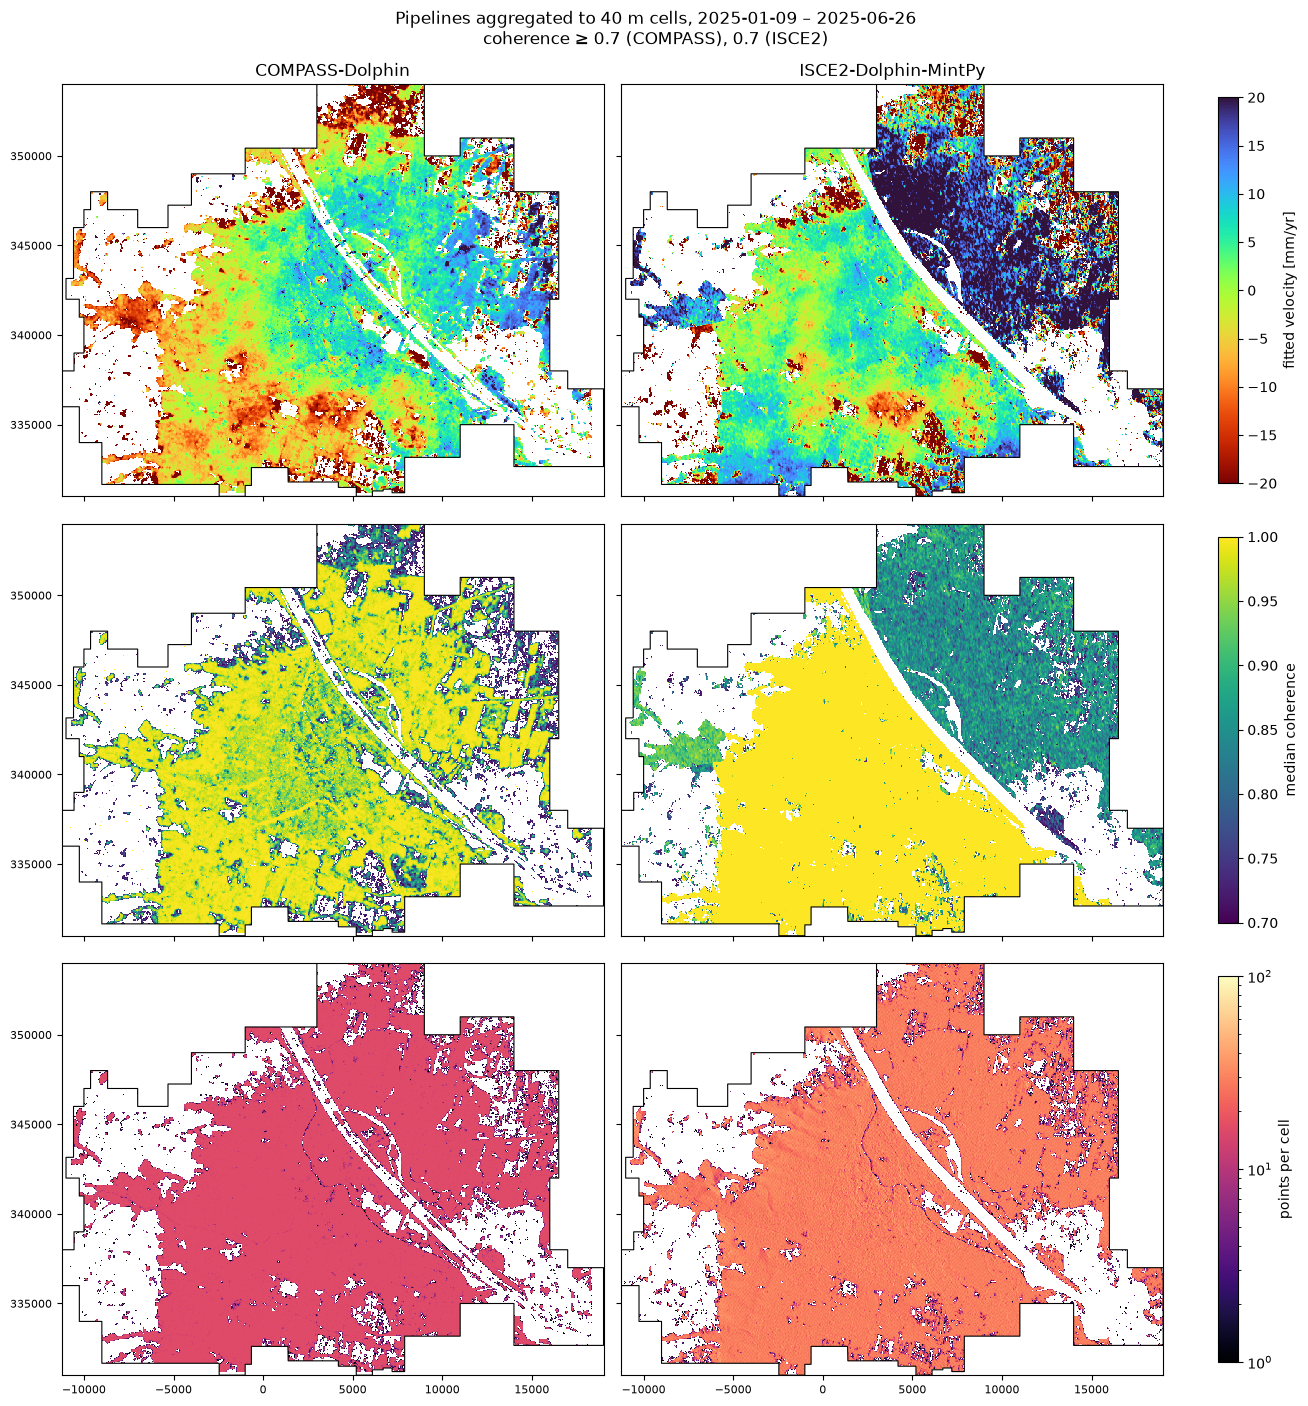

In [9]:
fig, axes = plt.subplots(3, 2, figsize=(13, 14), sharex=True, sharey=True, constrained_layout=True)
map_rows = [
    ("velocity_fit", CMAP, Normalize(-VEL_LIMIT, VEL_LIMIT), "fitted velocity [mm/yr]"),
    ("coherence", "viridis", Normalize(0.7, 1), "median coherence"),
    ("count", "magma", LogNorm(1, 100), "points per cell"),
]
for col, (name, stats) in enumerate(cell_stats.items()):
    axes[0, col].set_title(name)
    for row, (column, cmap, norm, _) in enumerate(map_rows):
        axes[row, col].imshow(grid.to_image(stats[column]), extent=grid.extent, cmap=cmap, norm=norm,
                              interpolation="nearest")
        style_map(axes[row, col])
for row, (_, cmap, norm, label) in enumerate(map_rows):
    fig.colorbar(ScalarMappable(norm, cmap), ax=axes[row], shrink=0.9, label=label)
fig.suptitle(f"Pipelines aggregated to {GRID_SIZE_M} m cells, 2025-01-09 – 2025-06-26\n{COH_INFO}")
plt.show()

## 4. Velocity comparison between the pipelines

### 4.1 Common reference on commonly stable cells

Same iterative procedure as notebook 03 section 4: offset = median velocity over cells that are stable
(|v − offset| ≤ `STABLE_TOL`) in both pipelines. The two pipelines use different reference points, so a constant
offset is expected. The same stable cells are used later to align the time series per date (section 6).

In [10]:
common_cells = alignment.common_values(cell_stats, "velocity_fit", min_count=STABLE_MIN_POINTS)
offsets, stable_cells, iteration = alignment.stable_offsets(common_cells, tol=STABLE_TOL)
VELOCITY_OFFSET = offsets if ALIGN_TO_STABLE else offsets * 0.0
ALIGN_INFO = f"aligned on {len(stable_cells):,} commonly stable cells" if ALIGN_TO_STABLE else "raw"
print(f"Common cells: {len(common_cells):,}, commonly stable: {len(stable_cells):,} "
      f"({100 * len(stable_cells) / len(common_cells):.1f} %), {iteration} iterations")
show(pd.DataFrame({"offset [mm/yr]": offsets,
                   "NMAD over stable cells [mm/yr]": common_cells.loc[stable_cells].apply(nmad)}).T)

Common cells: 196,241, commonly stable: 3,400 (1.7 %), 41 iterations


,COMPASS-Dolphin,ISCE2-Dolphin-MintPy
offset [mm/yr],1.29,2.71
NMAD over stable cells [mm/yr],0.74,0.70


### 4.2 Metrics, scatter and differences

Velocities over ~5.5 months are noisy (a 1 mm displacement error is already ~2 mm/yr), so expect
a larger spread than in the 3-year comparison of notebook 03.

In [11]:
def used_velocity(name, column="velocity_fit"):
    s = cell_stats[name]
    return s.loc[s["count"] >= MIN_POINTS_PER_CELL, column]


def compare(aligned=ALIGN_TO_STABLE, column="velocity_fit"):
    df = pd.concat({n: used_velocity(n, column) for n in PIPELINES}, axis=1, join="inner").dropna()
    return df - VELOCITY_OFFSET if aligned else df


def pair_metrics(df):
    """difference_metrics SECOND − FIRST plus the cells that only one pipeline has."""
    m = metrics.difference_metrics(df[FIRST], df[SECOND])
    return {"N": m.pop("N"),
            f"cells only in {SHORT[FIRST]}": len(used_velocity(FIRST)) - len(df),
            f"cells only in {SHORT[SECOND]}": len(used_velocity(SECOND)) - len(df), **m}


comparison = compare()
vel_metrics = pd.DataFrame({
    "fitted velocity, raw": pair_metrics(compare(aligned=False)),
    "fitted velocity, aligned": pair_metrics(comparison),
    "provider velocity, aligned*": pair_metrics(
        compare(aligned=False, column="velocity_provider").pipe(lambda df: df - df.loc[df.index.intersection(stable_cells)].median())),
})
print(f"Difference = {SECOND} − {FIRST}.  *provider velocities aligned on their own median over the stable cells")
show(vel_metrics, int_labels=("N", f"cells only in {SHORT[FIRST]}", f"cells only in {SHORT[SECOND]}"))

Difference = ISCE2-Dolphin-MintPy − COMPASS-Dolphin.  *provider velocities aligned on their own median over the stable cells


,"fitted velocity, raw","fitted velocity, aligned","provider velocity, aligned*"
N,"202,667","202,667","202,667"
cells only in COMPASS,"5,774","5,774","5,774"
cells only in ISCE2,"18,669","18,669","18,669"
bias [mm/yr],7.74,6.32,7.74
median diff. [mm/yr],6.74,5.32,6.42
MAE [mm/yr],9.17,8.30,9.45
RMSE [mm/yr],12.48,11.65,13.09
std diff. [mm/yr],9.79,9.79,10.56
NMAD [mm/yr],8.15,8.15,8.94
|diff| ≤ 2 mm/yr [%],18.39,21.52,18.62


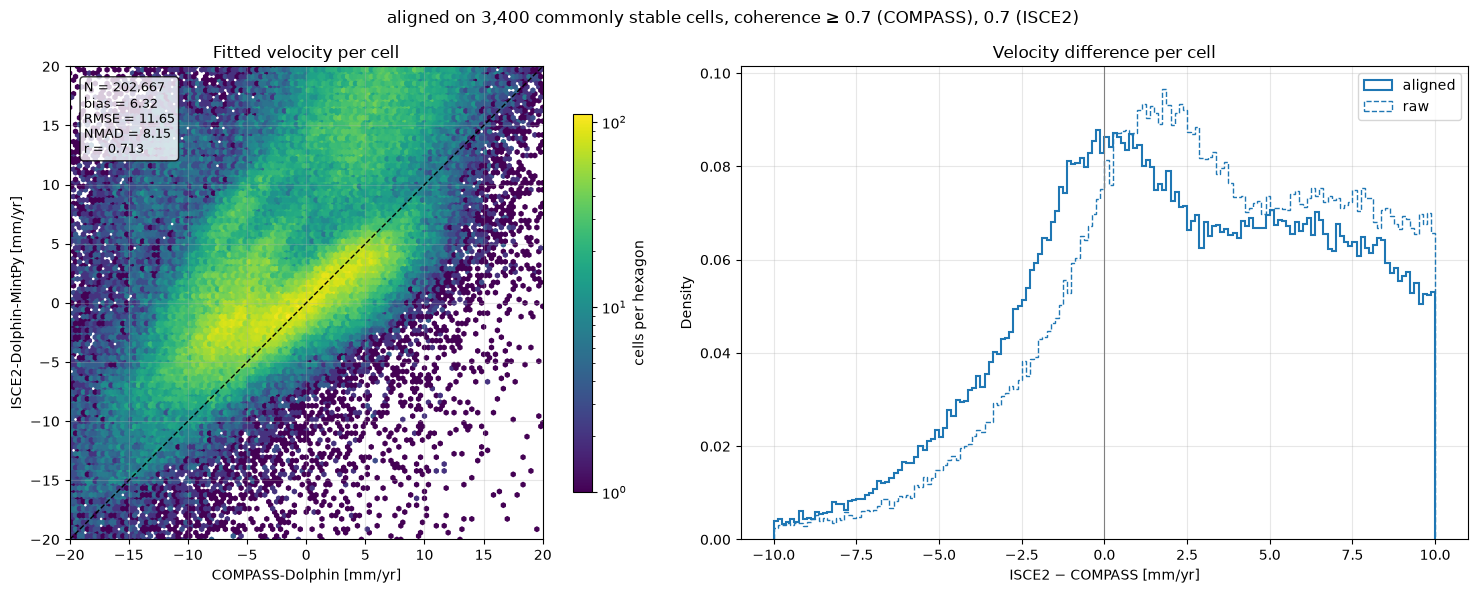

In [12]:
diff = comparison[SECOND] - comparison[FIRST]
fig, (ax_sc, ax_h) = plt.subplots(1, 2, figsize=(15, 6), gridspec_kw={"width_ratios": [1, 1.2]})
hb = ax_sc.hexbin(comparison[FIRST], comparison[SECOND], gridsize=120, bins="log", mincnt=1, cmap="viridis",
                  extent=(-VEL_LIMIT, VEL_LIMIT, -VEL_LIMIT, VEL_LIMIT))
ax_sc.plot([-VEL_LIMIT, VEL_LIMIT], [-VEL_LIMIT, VEL_LIMIT], "k--", lw=1)
metrics_box(ax_sc, vel_metrics["fitted velocity, aligned"])
ax_sc.set(xlim=(-VEL_LIMIT, VEL_LIMIT), ylim=(-VEL_LIMIT, VEL_LIMIT), aspect="equal",
          xlabel=f"{FIRST} [mm/yr]", ylabel=f"{SECOND} [mm/yr]", title="Fitted velocity per cell")
ax_sc.grid(alpha=0.3)
fig.colorbar(hb, ax=ax_sc, shrink=0.8, label="cells per hexagon")

bins = np.linspace(-DIFF_LIMIT, DIFF_LIMIT, 161)
raw = compare(aligned=False)
ax_h.hist(diff, bins=bins, density=True, histtype="step", lw=1.5, color="C0", label="aligned")
ax_h.hist(raw[SECOND] - raw[FIRST], bins=bins, density=True, histtype="step", lw=1, ls="--", color="C0", label="raw")
ax_h.axvline(0, color="0.5", lw=0.8)
ax_h.set(xlabel=f"{SHORT[SECOND]} − {SHORT[FIRST]} [mm/yr]", ylabel="Density", title="Velocity difference per cell")
ax_h.grid(alpha=0.3)
ax_h.legend()
fig.suptitle(f"{ALIGN_INFO}, {COH_INFO}")
plt.tight_layout()
plt.show()

### 4.3 Difference map

Left: velocity difference per cell. Right: the same after removing the smooth part (Gaussian, σ = `HIGHPASS_SIGMA_M`),
so that sharp boundaries stand out. A burst-edge artifact present in only one pipeline appears as a straight
step along the dashed edges.

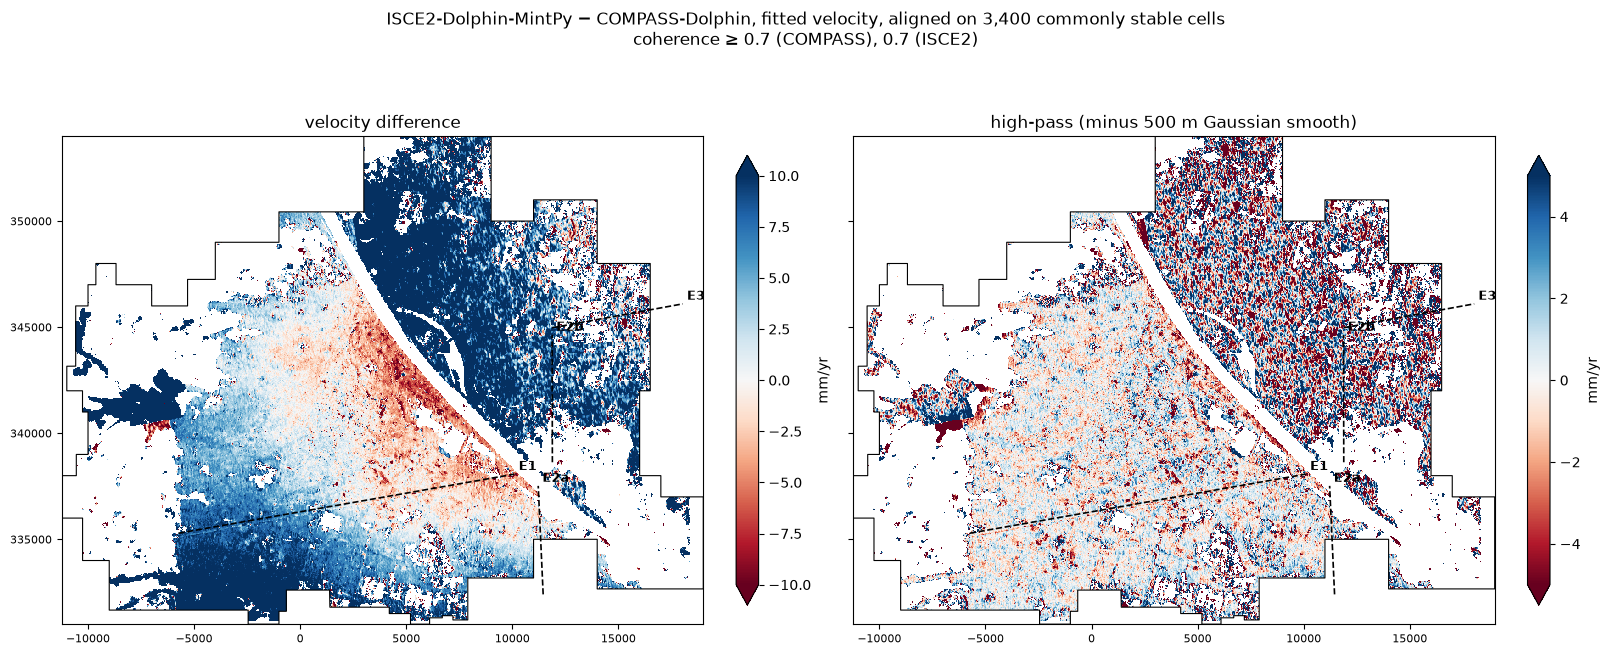

In [13]:
def highpass(values, sigma_m=HIGHPASS_SIGMA_M):
    """Per-cell values minus a NaN-aware Gaussian smooth of them (image)."""
    return grid.highpass(values, sigma_m)


fig, axes = plt.subplots(1, 2, figsize=(16, 7), sharex=True, sharey=True, constrained_layout=True)
norm = Normalize(-DIFF_LIMIT, DIFF_LIMIT)
hp_norm = Normalize(-DIFF_LIMIT / 2, DIFF_LIMIT / 2)
axes[0].imshow(grid.to_image(diff), extent=grid.extent, cmap="RdBu", norm=norm, interpolation="nearest")
axes[1].imshow(highpass(diff), extent=grid.extent, cmap="RdBu", norm=hp_norm, interpolation="nearest")
for ax, title in zip(axes, ["velocity difference", f"high-pass (minus {HIGHPASS_SIGMA_M} m Gaussian smooth)"]):
    style_map(ax)
    draw_edges(ax)
    ax.set_title(title)
fig.colorbar(ScalarMappable(norm, "RdBu"), ax=axes[0], shrink=0.7, extend="both", label="mm/yr")
fig.colorbar(ScalarMappable(hp_norm, "RdBu"), ax=axes[1], shrink=0.7, extend="both", label="mm/yr")
fig.suptitle(f"{SECOND} − {FIRST}, fitted velocity, {ALIGN_INFO}\n{COH_INFO}")
plt.show()

### 4.4 Comparison per side of the Danube

The maps above show the largest difference not at burst edges but across the Danube: north-east of the river ISCE2
has much higher velocities and a lower temporal coherence. The metrics are therefore repeated per river side.

In [14]:
_, d_side, _ = edge_coords(*TO_LONLAT.transform(*grid.centres(comparison.index)), *DANUBE)
side_of_cell = pd.Series(np.where(d_side > 0, "north-east", "south-west"), index=comparison.index)
per_side = {}
for side in ["south-west", "north-east"]:
    df = comparison[side_of_cell == side]
    m = pair_metrics(df)
    per_side[side] = {k: v for k, v in m.items() if "only in" not in k}
    for n in PIPELINES:
        per_side[side][f"median velocity {SHORT[n]} [mm/yr]"] = df[n].median()
        per_side[side][f"median coherence {SHORT[n]}"] = cell_stats[n].loc[df.index, "coherence"].median()
print(f"Aligned fitted velocities, difference = {SECOND} − {FIRST}")
show(pd.DataFrame(per_side), int_labels=("N",))

Aligned fitted velocities, difference = ISCE2-Dolphin-MintPy − COMPASS-Dolphin


,south-west,north-east
N,"130,176","72,491"
bias [mm/yr],3.88,10.71
median diff. [mm/yr],2.44,11.02
MAE [mm/yr],6.01,12.43
RMSE [mm/yr],9.09,15.20
std diff. [mm/yr],8.22,10.79
NMAD [mm/yr],5.75,7.22
|diff| ≤ 2 mm/yr [%],30.29,5.76
Pearson r,0.66,0.75
Spearman ρ,0.52,0.64


## 5. S1A / S1C burst-edge check

### 5.1 Offset maps

Top: `s1c_offset` per cell, i.e. what the S1C dates show on top of their S1A neighbours
(mean over the S1C dates, median removed). Middle: the same high-pass filtered. A misregistration artifact is
constant within a burst and jumps at the edges, so it shows up as straight steps along the dashed lines.
Bottom: the S1A-only control offset (high-pass): it contains the same kind of noise but no mission
difference, so edges should be invisible there.

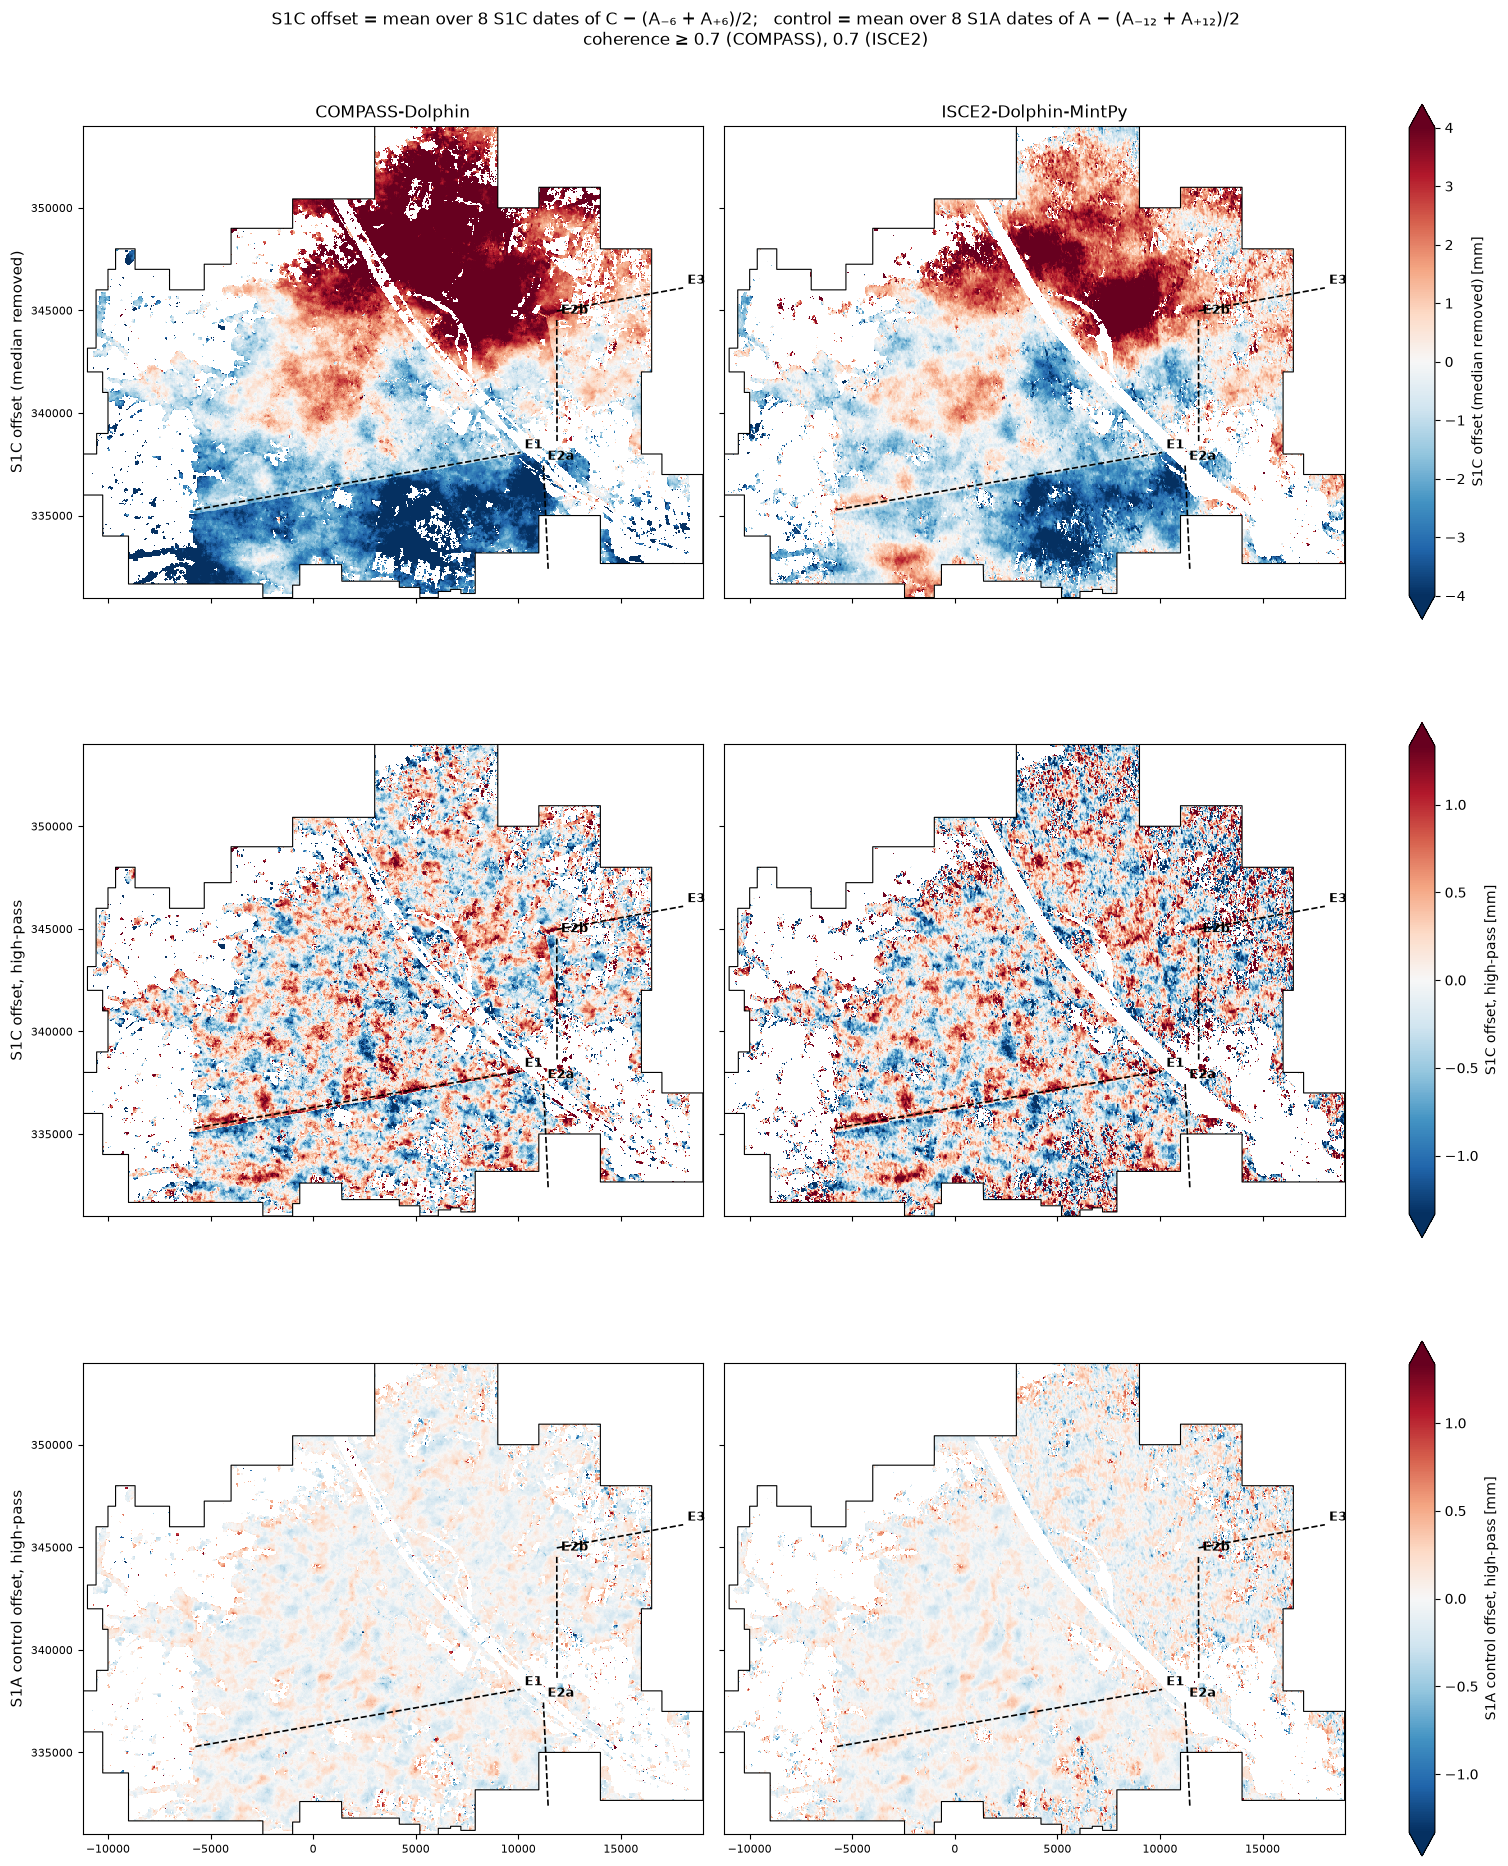

In [15]:
fig, axes = plt.subplots(3, 2, figsize=(15, 19), sharex=True, sharey=True, constrained_layout=True)
off_norm = Normalize(-OFFSET_LIMIT, OFFSET_LIMIT)
hp_norm = Normalize(-OFFSET_LIMIT / 3, OFFSET_LIMIT / 3)
for col, (name, stats) in enumerate(cell_stats.items()):
    axes[0, col].imshow(grid.to_image(stats["s1c_offset"] - stats["s1c_offset"].median()), extent=grid.extent,
                        cmap="RdBu_r", norm=off_norm, interpolation="nearest")
    axes[1, col].imshow(highpass(stats["s1c_offset"]), extent=grid.extent, cmap="RdBu_r", norm=hp_norm,
                        interpolation="nearest")
    axes[2, col].imshow(highpass(stats["control_offset"]), extent=grid.extent, cmap="RdBu_r", norm=hp_norm,
                        interpolation="nearest")
    axes[0, col].set_title(name)
    for ax in axes[:, col]:
        style_map(ax)
        draw_edges(ax, labels=True)
labels = ["S1C offset (median removed)", "S1C offset, high-pass", "S1A control offset, high-pass"]
for row, (lab, nrm) in enumerate(zip(labels, [off_norm, hp_norm, hp_norm])):
    axes[row, 0].set_ylabel(lab, fontsize=11)
    fig.colorbar(ScalarMappable(nrm, "RdBu_r"), ax=axes[row], shrink=0.85, extend="both", label=f"{lab} [mm]")
fig.suptitle(f"S1C offset = mean over {len(TRIPLETS)} S1C dates of C − (A₋₆ + A₊₆)/2;   "
             f"control = mean over {len(CONTROL)} S1A dates of A − (A₋₁₂ + A₊₁₂)/2\n{COH_INFO}")
plt.show()

### 5.2 Step across each edge

For each edge and pipeline, the points within `STEP_HALF_WIDTH_M` of the segment are binned by their distance to it
(`PROFILE_BIN_M`, median per bin). A straight line plus a jump at distance 0 is fitted to the bins
(bins closer than `STEP_GAP_M` left out):

`value(d) = a + b·d + step·[d > 0]`

The linear term absorbs smooth gradients (atmosphere, deformation, ramps) that would bias a simple
"median left − median right". The step is fitted for every date of the displacement time series, for
the S1C offset, the control offset and the fitted velocity.

**What to look for**: if the S1C dates have a step and the S1A dates do not (a saw-tooth in the per-date
plot), the artifact is there. Errors on the reference date propagate to all dates, so look at the
difference between S1C and S1A dates rather than at the absolute level.

In [16]:
def binned_profile(dist, values):
    """Median of `values` (n x k) per distance bin -> DataFrame indexed by bin centre."""
    b = (np.floor(dist / PROFILE_BIN_M) + 0.5) * PROFILE_BIN_M
    return pd.DataFrame(values).groupby(b).median()


def step_fit(profile):
    """Step at d = 0 of a + b·d + step·[d > 0], fitted per column of a binned profile. Returns (step, step std)."""
    d = profile.index.to_numpy()
    use = np.abs(d) > STEP_GAP_M
    steps, sigmas = [], []
    for col in profile.columns:
        y = profile[col].to_numpy()
        ok = use & np.isfinite(y)
        if (ok & (d > 0)).sum() < 3 or (ok & (d < 0)).sum() < 3:
            steps.append(np.nan); sigmas.append(np.nan)
            continue
        A = np.column_stack([np.ones(ok.sum()), d[ok], (d[ok] > 0).astype(float)])
        coef, res, *_ = np.linalg.lstsq(A, y[ok], rcond=None)
        dof = max(ok.sum() - 3, 1)
        s2 = (np.sum((y[ok] - A @ coef) ** 2)) / dof
        sigmas.append(np.sqrt(s2 * np.linalg.inv(A.T @ A)[2, 2]))
        steps.append(coef[2])
    return np.array(steps), np.array(sigmas)


edge_results = {}      # (edge, pipeline) -> dict
for edge, (p1, p2) in EDGES.items():
    for name, pts in points.items():
        along, dist, length = edge_coords(pts["lon"].to_numpy(), pts["lat"].to_numpy(), p1, p2)
        near = (along >= 0) & (along <= length) & (np.abs(dist) <= STEP_HALF_WIDTH_M)
        if near.sum() < 100:
            continue
        values = np.column_stack([series[name][near],
                                  pts.loc[near, ["s1c_offset", "control_offset", "velocity_fit"]].to_numpy()])
        prof = binned_profile(dist[near], values)
        prof.columns = TS_COLS + ["s1c_offset", "control_offset", "velocity_fit"]
        step, sigma = step_fit(prof)
        edge_results[(edge, name)] = dict(
            profile=prof, step=pd.Series(step, index=prof.columns), sigma=pd.Series(sigma, index=prof.columns),
            n_left=int((dist[near] > 0).sum()), n_right=int((dist[near] < 0).sum()))
print(f"Step fits done for {len(edge_results)} edge / pipeline combinations")

Step fits done for 8 edge / pipeline combinations


Per edge: left, the step of the displacement on every date (S1A circles, S1C squares; error bars = 1σ of the fit).
Right, the profile of the S1C offset across the edge with the fitted model.

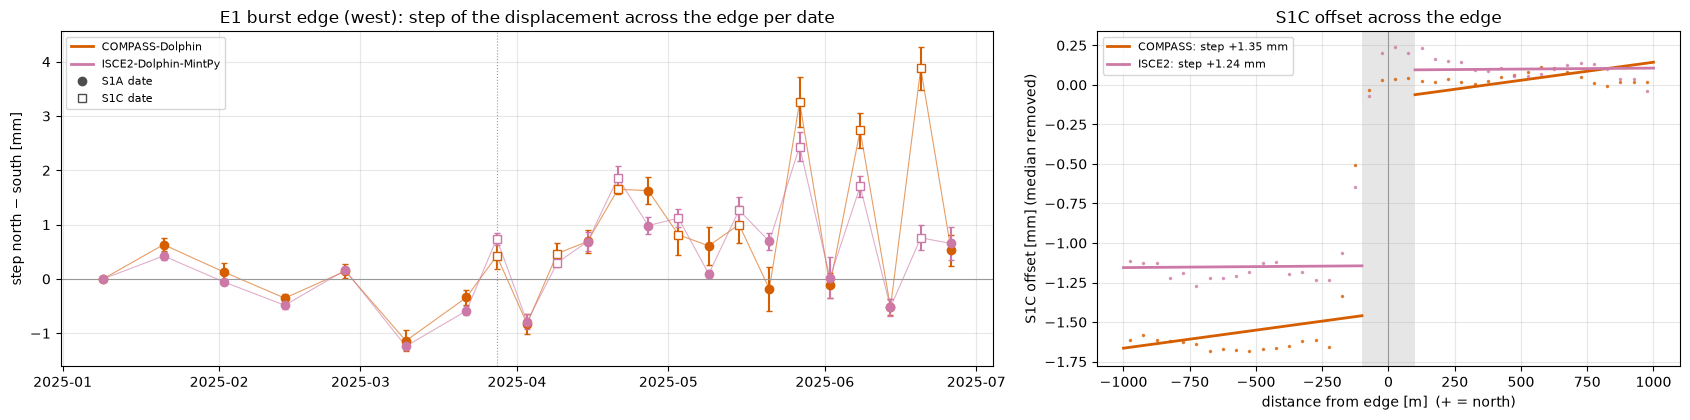

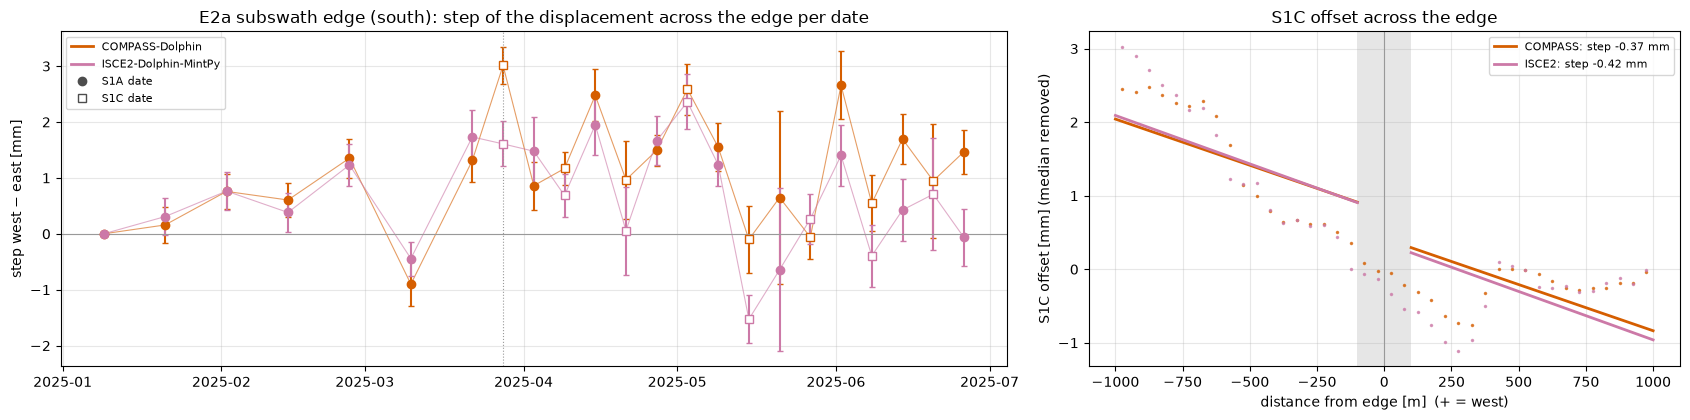

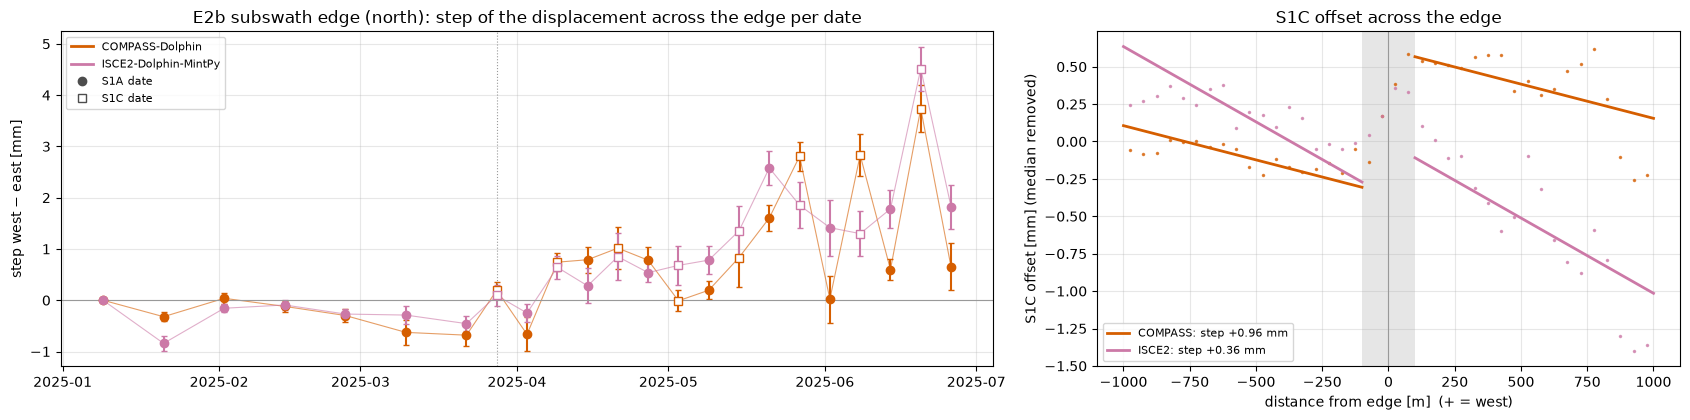

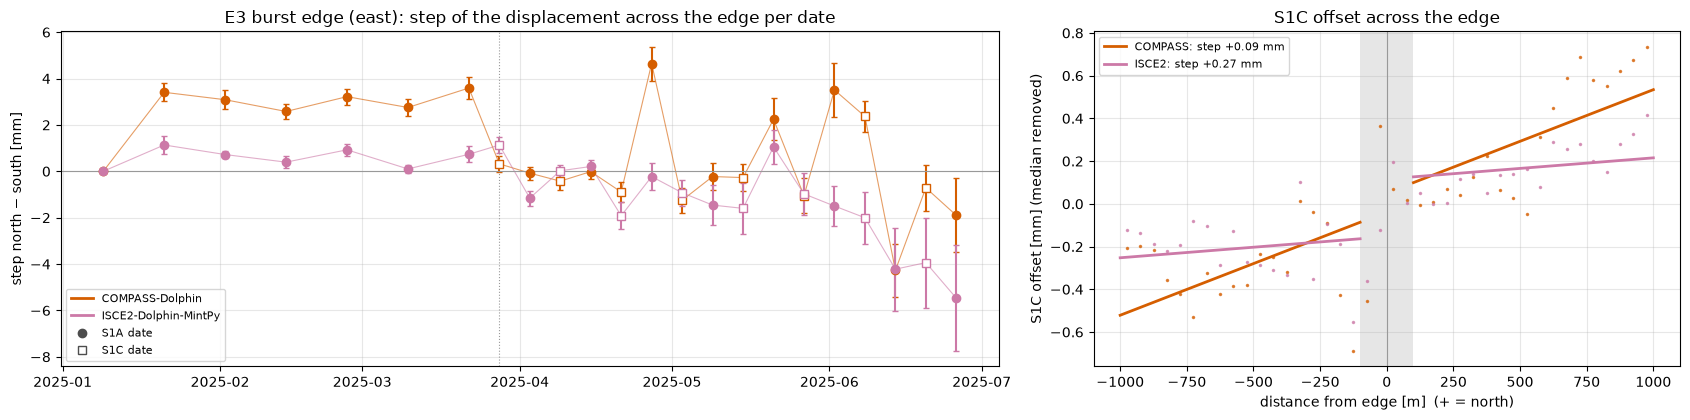

In [17]:
for edge, (p1, p2) in EDGES.items():
    left, right = side_names(p1, p2)
    fig, (ax_t, ax_p) = plt.subplots(1, 2, figsize=(17, 4.3), gridspec_kw={"width_ratios": [1.6, 1]})
    for name, cfg in PIPELINES.items():
        r = edge_results.get((edge, name))
        if r is None:
            continue
        st, sg = r["step"][TS_COLS].to_numpy(), r["sigma"][TS_COLS].to_numpy()
        ax_t.plot(DATES, st, color=cfg.color, lw=0.8, alpha=0.6)
        for mission, style in MISSION_STYLE.items():
            sel = MISSION == mission
            ax_t.errorbar(DATES[sel], st[sel], yerr=sg[sel], ls="none", color=cfg.color, ms=6,
                          mfc=cfg.color if mission == "S1A" else "white", capsize=2, marker=style["marker"])

        prof = r["profile"]["s1c_offset"]
        d = prof.index.to_numpy()
        ax_p.plot(d, prof.to_numpy() - np.nanmedian(prof), ".", color=cfg.color, ms=3, alpha=0.7)
        # fitted model (refit for drawing)
        ok = (np.abs(d) > STEP_GAP_M) & np.isfinite(prof.to_numpy())
        A = np.column_stack([np.ones(ok.sum()), d[ok], (d[ok] > 0)])
        coef = np.linalg.lstsq(A, prof.to_numpy()[ok], rcond=None)[0]
        for sign in (-1, 1):
            dd = np.array([sign * STEP_GAP_M, sign * STEP_HALF_WIDTH_M])
            ax_p.plot(dd, coef[0] + coef[1] * dd + coef[2] * (sign > 0) - np.nanmedian(prof), color=cfg.color,
                      lw=2, label=f"{SHORT[name]}: step {coef[2]:+.2f} mm" if sign > 0 else None)

    ax_t.axhline(0, color="0.6", lw=0.8)
    ax_t.axvline(DATES[TRIPLETS[0][0]], color="0.6", lw=0.8, ls=":")
    ax_t.set_ylabel(f"step {left} − {right} [mm]")
    ax_t.set_title(f"{edge}: step of the displacement across the edge per date")
    ax_t.grid(alpha=0.3)
    handles = [Line2D([], [], color=c.color, lw=2, label=n) for n, c in PIPELINES.items()] + [
        Line2D([], [], color="0.3", marker="o", ls="none", label="S1A date"),
        Line2D([], [], color="0.3", marker="s", mfc="white", ls="none", label="S1C date")]
    ax_t.legend(handles=handles, fontsize=8, loc="best")

    ax_p.axvline(0, color="0.6", lw=0.8)
    ax_p.axvspan(-STEP_GAP_M, STEP_GAP_M, color="0.9", lw=0)
    ax_p.set_xlabel(f"distance from edge [m]  (+ = {left})")
    ax_p.set_ylabel("S1C offset [mm] (median removed)")
    ax_p.set_title("S1C offset across the edge")
    ax_p.grid(alpha=0.3)
    ax_p.legend(fontsize=8)
    plt.tight_layout()
    plt.show()

### 5.3 Summary

* **step S1A / S1C dates**: mean step of the displacement on the S1A / S1C dates since the first S1C date
  (the S1A dates before are left out, they carry no S1C information),
* **S1C − S1A**: the saw-tooth amplitude, i.e. the jump the S1C dates add at this edge,
* **S1C offset step**: step of the mean S1C offset (independent estimate of the same quantity),
* **control step**: step of the S1A-only control offset (should be ≈ 0; its size is a noise level),
* **velocity step**: step of the fitted velocity.

As a rough rule, a step is significant if it is clearly larger than the control step and than its σ.

In [18]:
since_c = DATES >= DATES[TRIPLETS[0][0]]
rows = {}
for (edge, name), r in edge_results.items():
    st = r["step"][TS_COLS].to_numpy()
    a, c = st[since_c & ~IS_C], st[since_c & IS_C]
    left, right = side_names(*EDGES[edge])
    rows[(edge, SHORT[name])] = {
        "sides": f"{left} − {right}",
        "points (left / right)": f"{r['n_left']:,} / {r['n_right']:,}",
        "step S1A dates [mm]": np.nanmean(a),
        "step S1C dates [mm]": np.nanmean(c),
        "S1C − S1A [mm]": np.nanmean(c) - np.nanmean(a),
        "S1C offset step [mm]": r["step"]["s1c_offset"],
        "S1C offset step σ [mm]": r["sigma"]["s1c_offset"],
        "control step [mm]": r["step"]["control_offset"],
        "velocity step [mm/yr]": r["step"]["velocity_fit"],
    }
edge_summary = pd.DataFrame(rows).T
edge_summary.index.names = ["edge", "pipeline"]
num = edge_summary.columns[2:]
display(edge_summary.style.format({c: "{:+.2f}" for c in num}).background_gradient(
    cmap="Reds", subset=["S1C offset step [mm]"], vmin=0, vmax=2, gmap=edge_summary["S1C offset step [mm]"].abs()))

## 6. Time-series comparison per date

Cell-mean time series of both pipelines (referenced to the first date) are compared on the common cells.
Per date, the remaining constant offset between the pipelines is removed with the median over the commonly
stable cells of section 4. If the S1C dates are handled differently by the two pipelines, the spread of the
difference (NMAD) should be larger on S1C dates than on the neighbouring S1A dates.

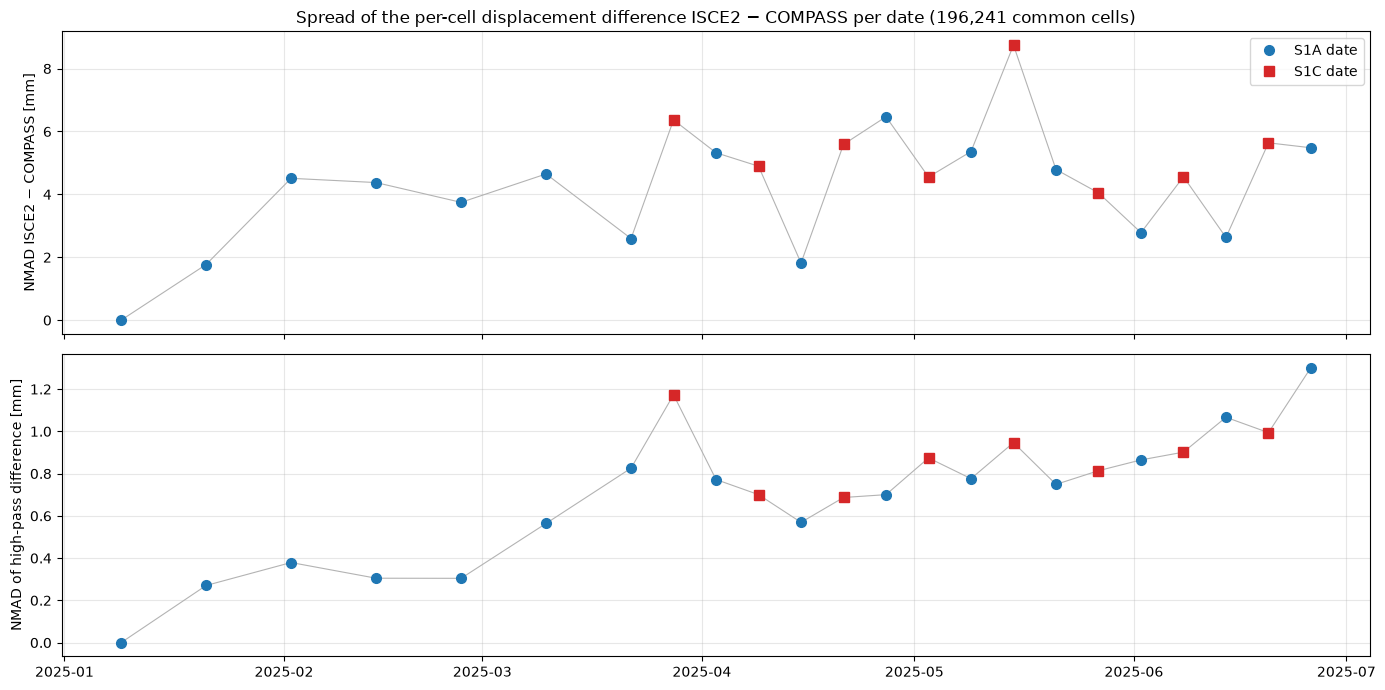

,NMAD ISCE2 − COMPASS [mm],NMAD of high-pass difference [mm]
mission,,
S1A,4.33,0.85
S1C,5.55,0.89


In [19]:
ts_cells = cell_ts[FIRST].index.intersection(cell_ts[SECOND].index).intersection(common_cells.index)
ts_diff = cell_ts[SECOND].loc[ts_cells] - cell_ts[FIRST].loc[ts_cells]
ts_diff = ts_diff - ts_diff.loc[ts_diff.index.intersection(stable_cells)].median()

per_date = pd.DataFrame({
    "mission": MISSION,
    f"NMAD {SHORT[SECOND]} − {SHORT[FIRST]} [mm]": ts_diff.apply(nmad).to_numpy(),
    f"NMAD of high-pass difference [mm]": [nmad(highpass(ts_diff[d])) for d in DATES],
}, index=DATES)

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 7), sharex=True)
for ax, col in zip((ax1, ax2), per_date.columns[1:]):
    ax.plot(DATES, per_date[col], color="0.7", lw=0.8)
    for mission, style in MISSION_STYLE.items():
        sel = MISSION == mission
        ax.plot(DATES[sel], per_date.loc[sel, col], ls="none", color="C3" if mission == "S1C" else "C0", ms=7,
                **style)
    ax.set_ylabel(col)
    ax.grid(alpha=0.3)
ax1.legend()
ax1.set_title(f"Spread of the per-cell displacement difference {SHORT[SECOND]} − {SHORT[FIRST]} per date "
              f"({len(ts_cells):,} common cells)")
plt.tight_layout()
plt.show()

since = DATES >= DATES[TRIPLETS[0][0]]
show(per_date[since].groupby("mission")[per_date.columns[1:]].mean())

Difference maps of a few dates (high-pass): the last S1A date before S1C, and the first and last S1C dates with
their S1A neighbours.

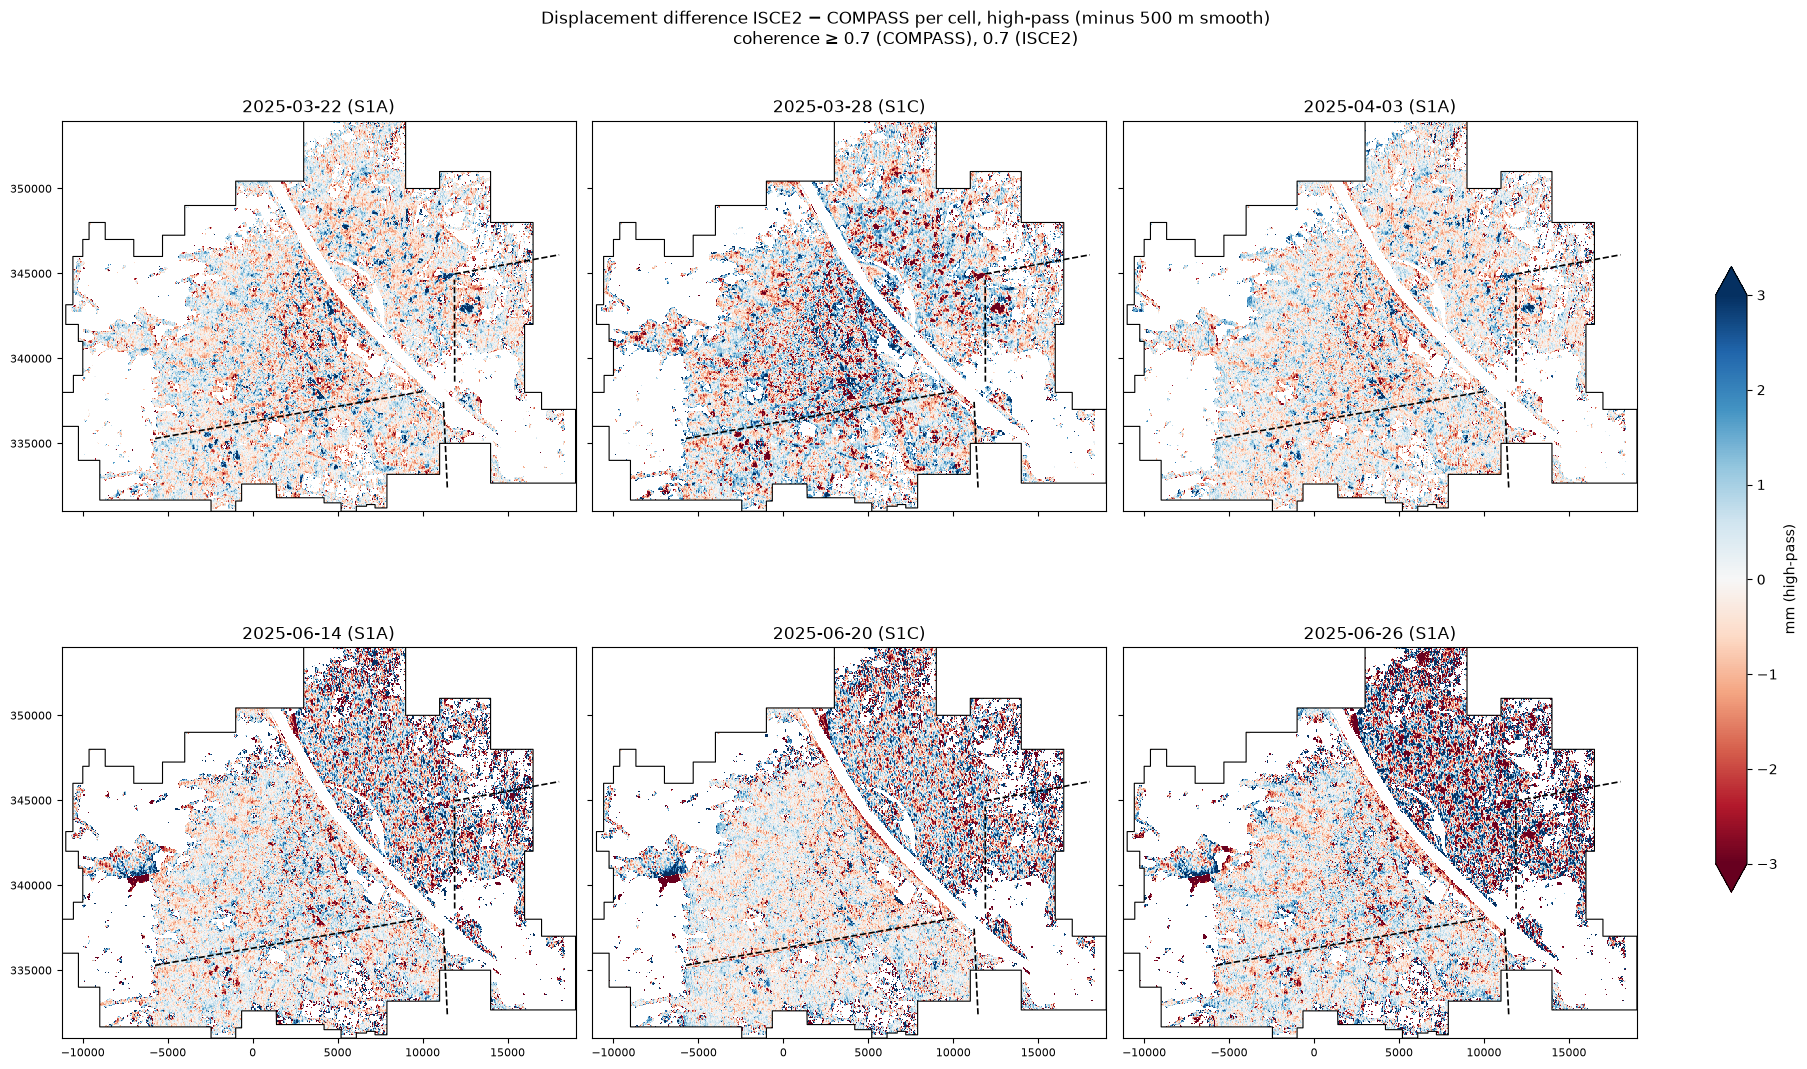

In [20]:
show_idx = sorted({TRIPLETS[0][1], TRIPLETS[0][0], TRIPLETS[0][2], TRIPLETS[-1][1], TRIPLETS[-1][0], TRIPLETS[-1][2]})
fig, axes = plt.subplots(2, 3, figsize=(18, 11), sharex=True, sharey=True, constrained_layout=True)
hp_norm = Normalize(-3, 3)
for ax, i in zip(axes.ravel(), show_idx):
    ax.imshow(highpass(ts_diff[DATES[i]]), extent=grid.extent, cmap="RdBu", norm=hp_norm, interpolation="nearest")
    style_map(ax)
    draw_edges(ax, labels=False)
    ax.set_title(f"{DATES[i]:%Y-%m-%d} ({MISSION[i]})")
fig.colorbar(ScalarMappable(hp_norm, "RdBu"), ax=axes, shrink=0.6, extend="both", label="mm (high-pass)")
fig.suptitle(f"Displacement difference {SHORT[SECOND]} − {SHORT[FIRST]} per cell, high-pass "
             f"(minus {HIGHPASS_SIGMA_M} m smooth)\n{COH_INFO}")
plt.show()

## Notes

**Findings of the first run (2026-11-10, coherence ≥ 0.7 for both).** The numbers are typed in by hand; re-check them after changing settings.

*Burst-edge artifact (section 5)*
- Both runs use the same 23 SAFE files: 15 S1A dates and 8 S1C dates (2025-03-28 – 06-20).
- **E1 (burst edge, west): the S1C artifact is present in both pipelines.** S1C offset step +1.35 ± 0.15 mm (COMPASS)
  and +1.24 ± 0.08 mm (ISCE2), compared with control steps of +0.04 / −0.09 mm. The per-date plot shows the same saw-tooth
  in both pipelines: the step jumps on S1C dates (up to 3–4 mm in June) and the S1A dates follow a smooth trend.
  The ISCE2 profile has a sharp step exactly at the edge, so **NESD did not remove it**.
- **E2b (subswath edge, north):** +0.96 ± 0.13 mm (COMPASS) vs +0.36 ± 0.17 mm (ISCE2). The step is smaller in ISCE2
  but not zero.
- E2a and E3: no clear S1C step (|step| ≲ 0.4 mm, about the size of σ). E3 lies in the area north-east of the Danube
  where ISCE2 has the large-scale problem described below.
- ESD estimates and removes a constant azimuth misregistration per acquisition. The step that remains after NESD
  suggests that the S1A/S1C phase jump is not only a coregistration offset. Possible causes are differences between
  S1A and S1C products in burst timing, Doppler centroid or azimuth FM-rate annotation; this notebook cannot tell them apart.
  Next checks: (1) the NESD azimuth offsets that ISCE2 estimated for the S1C dates (`misreg/azimuth` in the topsStack work dir);
  (2) single S1A–S1C interferograms at the E1 burst overlap, before phase linking.

*Pipeline differences (sections 4 and 6)*
- The velocity comparison is dominated by large-scale differences, not by burst edges. North-east of the Danube, ISCE2 is
  about +11 mm/yr higher than COMPASS (median 15.0 vs 3.6 mm/yr), and its temporal coherence there is lower (0.85 vs 1.00
  south-west of the river). `conncomp_ok` does not explain this. Possible causes are unwrapping across the river (SNAPHU
  2×2 tiles) or the MintPy quadratic deramp / ERA5 correction. COMPASS-Dolphin has none of these corrections.
- South-west of the Danube the median difference is +2.4 mm/yr (NMAD 5.8 mm/yr), with a smooth west–east gradient.
  This gradient is consistent with the ERA5 correction and deramp that only ISCE2 applies.
- The velocities cover only 5.5 months, so 1 mm of displacement error is already ~2 mm/yr. Do not over-interpret
  the velocity numbers, and use the time-series and burst-edge checks for the S1C question.
- Per date (section 6), the pipelines disagree slightly more on S1C dates (NMAD 5.6 vs 4.3 mm). After high-pass filtering,
  the S1C and S1A dates are equal (0.89 vs 0.85 mm). The extra disagreement on S1C dates is therefore large-scale
  (atmosphere / ramp) rather than sharp edges, which fits with both pipelines having the same edge artifact.